In [27]:
import Pyro4
import numpy as np
import matplotlib.pyplot as plt
import threading
import time
import os, ntpath
import sys, shutil
from pathlib import Path
from lmfit import Model, create_params
from lmfit.models import LinearModel, LorentzianModel, GaussianModel, VoigtModel, PolynomialModel, ConstantModel

from scipy.fft import fft, ifft, fftfreq

def my_find_nearest(ar,target):
    index = (np.abs(ar - target)).argmin()
    return index


def exponential(t, tau, A):
    return np.exp(-t/tau)*A

def power_law(t, lambd, t0, A):
    return A*t**(-lambd)

def power_law_times_exp(t, tau, t0,lambd, A):
    return A*(t/t0)**(-lambd)*np.exp(-t/tau)

exp_model = Model(exponential, independent_vars=['t'], param_names = ['tau','A'])
powerlaw_model = Model(power_law, independent_vars=['t'], param_names = ['lambd','t0','A'])
powerlaw_exponential_model = Model(power_law_times_exp, independent_vars=['t'], param_names = ['tau', 't0','lambd', 'A'])

## SET UP CLIENT SERVER CONNECTION
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"          
Pyro4.config.THREADPOOL_SIZE = 40           
Pyro4.config.THREADPOOL_SIZE_MIN = 4

URI = "PYRO:Analysis_g13@127.0.0.1:9098"
# URI = "PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098"
try:
    stop_logs.set()
except:
    pass

def g2izer(tau, hist, t_acq_tot_s, n_new_bins=None, ref_range_s=None,verbose = False):
    if n_new_bins is not None and isinstance(n_new_bins, int):
        if verbose: 
            print(f"Rebinning from {len(tau):d} to {n_new_bins:d}")
        tau_rebin, h_rebin = re_bin(tau*1e9,hist, int(n_new_bins))
        tau_rebin = (tau_rebin).astype(float)*1e-9

        # Apply biased norm (acceptance)
        g2_biased_norm = t_acq_tot_s - tau_rebin
        h_rebin = h_rebin.astype(float)/g2_biased_norm

    else:
        if verbose: 
            print("Not rebinning")
        tau_rebin, h_rebin = (tau, hist)
    
    binsize = (tau_rebin[1]-tau_rebin[0]) # bin size in ns
    if verbose: 
            print("Bin size ", binsize*1e9, " ns")
    
    # Filter out extreme outliars
    # stdv_h_raw = np.std(h_rebin)
    # mean_h_raw = np.mean(h_rebin)
    #mask_outliars = np.abs(h_rebin - mean_h_raw) < 1e9*stdv_h_raw #7*stdv_h_raw
    #h_rebin = h_rebin[mask_outliars]
    #tau_rebin = tau_rebin[mask_outliars]
    
    if isinstance(ref_range_s, list) and all(isinstance(r, float) for r in ref_range_s):
        if verbose: 
            print(f"Reference range {ref_range_s} s used to correct linear background and show statistics")
            print('tau_rebin and indices',h_rebin,tau_rebin)#,my_find_nearest(tau_rebin, ref_range_s[0]),my_find_nearest(tau_rebin, ref_range_s[1]))
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        histo_bg = h_rebin[bg_range_tau[0]:bg_range_tau[1]]
        tau_bg = tau_rebin[bg_range_tau[0]:bg_range_tau[1]]
        # Evaluate statistics
        h_0 = np.mean(h_rebin[bg_range_tau[0]:bg_range_tau[1]])
        
        # Fit linear background
        # bg_fit = LinearModel()
        # linear_params = bg_fit.make_params(slope=(h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100])/h_0, intercept=1)
        # fitresult = bg_fit.fit(histo_bg/h_0, x = tau_bg)
        # print("Fit slope guess", (h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100]))
        # print("FIt intercept guess", np.mean(h_rebin))
        # print(fitresult.params)
        # lin_bg = fitresult.eval(x = tau_rebin)
        # h_rebin_detrend = h_rebin - lin_bg*h_0
        stdv_h = np.std(histo_bg)# - fitresult.eval(x = tau_bg))
        # 
        return tau_rebin, h_rebin, stdv_h, h_0 #tau_rebin, h_rebin_detrend, stdv_h, h_0
    else:
        return tau_rebin, h_rebin
    
def rebin_plot(tau, hist, n_new_bins=None, ref_range_s=None, lim_x_us= None,lim_y= None, pltname = None, savepath = None, h_offset = 0):
    plt.figure(figsize=(10,2.8))
    if ref_range_s is not None: 
        tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0+h_offset,"-o",markersize=4,label=r"Coincidences per bin")
        plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0+h_offset,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)

        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey')
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0])+h_offset,linestyle='solid',zorder=0,color='lightgrey',label="Mean")

        plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    else: 
        tau_rebin, h_rebin = g2izer(tau, hist, n_new_bins, ref_range_s)
        plt.plot(tau_rebin*1e6, h_rebin+h_offset,"-o",markersize=4, label=r"Coincidences per bin (uncorrected)")
        plt.ylabel("Raw coincidences")
    
    if lim_x_us is not None: 
        plt.xlim(-lim_x_us/50, lim_x_us)
        
    if lim_y is not None: 
        plt.ylim(lim_y[0], lim_y[1])
        
    plt.legend()#loc='upper right')
    plt.xlabel(r"Time delay $\tau$ (µs)")
    
    if pltname is not None: 
        plt.title(pltname +"\n"+ f"Time delay bin size = {int((tau_rebin[1]-tau_rebin[0])*1e9):d} ns")
    
    plt.tight_layout()
    if savepath is not None:
        plt.savefig(savepath,dpi = 200)
    
def get_crs(paths, chunkname=f'_chunk{c}',tau_bin_ms_class = None,chunk_range_class = (0,50), include_channel = 0):
    base, name, path = paths
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms_class, chunk_range = chunk_range_class, include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    # print("Indices of chunks loaded: ",np.array(chunk_index_list))
    # print("Chunk durations (min):",chunk_minutes_list)
    # print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    # print("Bin size (ms): ", np.array(dt_s_list)*1e3)

    #### FOR EACH CHUNK SEPARATELY:
    ch_id = 0
    # print("[DEBUG]: counts list looks like this:", np.shape(np.array(counts_list[ch_id])))

    nbins = np.shape(np.array(counts_list[ch_id]))[0]
    # print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    #print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[ch_id]))*dt_s_list[0]
    t_rebin,h_rebin = ( t*1e6,np.array(counts_list[ch_id]) )  #re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    bin_size = (t_rebin[1]-t_rebin[0])
    # print(f"Bin size: {bin_size:.3f}  s")
    return h_rebin, t_rebin


def analysis_setup():

    global analysis_cmd # only to pass comannds
    analysis_cmd = Pyro4.Proxy(URI)

    # Separate stop flag for the poller
    global stop_logs
    stop_logs = threading.Event()
    
        
    def log_poller():
        analysis_log = Pyro4.Proxy(URI)  # only for log
        idx = 0
        progress_active = False          # track if last print was a progress line
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        # progress update: overwrite same line, no newline
                        text = line[1:]  # strip the '\r' tag
                        sys.stdout.write('\r\033[K')
                        sys.stdout.write(text)
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write('\n')
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as e:
            #     # If poll fails, finish any in-place line so errors don’t append to it
                if progress_active:
                    sys.stdout.write('\n')
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {e}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)
            
    t = threading.Thread(target=log_poller, daemon=True)
    t.start()
    print("------------------ LOG ------------------", flush=True)

    analysis_cmd.ping()

def re_bin(tau_bins, h, n_new_bins_approx):
    
    n_original_bins = len(tau_bins)
    len_new_bins = n_original_bins // n_new_bins_approx
    n_new_bins = n_original_bins//len_new_bins           # to make sure we bin cleanly
    
    tau_rebin = np.zeros(n_new_bins,dtype = np.int64)
    h_rebin   = np.zeros(n_new_bins,dtype = np.int64)
    
    for n in range(n_new_bins):
        tau_rebin[n] = np.sum( tau_bins[ n*len_new_bins : (n+1)*len_new_bins ] ) // len_new_bins
        h_rebin  [n] = np.sum( h       [ n*len_new_bins : (n+1)*len_new_bins ] )
    

    return tau_rebin, h_rebin

In [ ]:
analysis_setup()
analysis_cmd.clear_log()


------------------ LOG ------------------
Analysis server reached.


Analysis server reached.
[ANALYSIS - UTC 2026-01-02 08:48:33] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:08] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:10] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:12] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:14] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.097_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:15] Reading file with name _chunk0 in

In [8]:
def analyze_all_gatemap(paths, ref_range_s,chunkname='all', g2mode = "all", classical_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = classical_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)
    
    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(1,4,figsize = (8,3))
    pltname = name.strip("\\").replace("\\", "_")[:-6]
    fig.suptitle(pltname+"\n"+f"Ch. {classical_channel}, mode {g2mode}")
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$"+f"(Mode {g2mode})")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms
    ############################################################
    plt.sca(ax[1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
      
    ############################################################
    # Count rates real - Channel 0
    ############################################################
    
    plt.sca(ax[2])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin - Ch. {classical_channel}")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])

    plt.sca(ax[3])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    fig.tight_layout()
    #fig.savefig(ntpath.join(base,f"Analysis_mode_{g2mode}.png"),dpi=300)
    plt.show()
    return h_rebin, t_rebin




Data from 22.12.2025

In [14]:
# B-field sweep at 4K at nu=-1 and VE=0

def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None, tau_bin_ms_class = None,
                chunk_range_class = (0,50), look_at_chunk = 0, ylims = (None,None), rebin_factor = 1, savepath = None, PDF_bins = None):
    base, name, path = paths
    g2_ylim, counts_ylim = ylims

    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)

    n_new_bins = int(len(tau)/rebin_factor)
    if ref_range_s is None:
        ref_range_s = [40e-3, 100e-3]
    t_acq_tot_s = params["chunk_ms"]*1e-3 * params["n_chunks"]
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist,t_acq_tot_s,  n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]



    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms_class, chunk_range = chunk_range_class, include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    # print("Indices of chunks loaded: ",np.array(chunk_index_list))
    # print("Chunk durations (min):",chunk_minutes_list)
    # print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    # print("Bin size (ms): ", np.array(dt_s_list)*1e3)

    #### FOR EACH CHUNK SEPARATELY:
    ch_id = look_at_chunk
    # print("[DEBUG]: counts list looks like this:", np.shape(np.array(counts_list[ch_id])))

    nbins = np.shape(np.array(counts_list[ch_id]))[0]
    # print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    #print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[ch_id]))*dt_s_list[0]
    t_rebin,h_rebin = ( t*1e6,np.array(counts_list[ch_id]) )  #re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    bin_size = (t_rebin[1]-t_rebin[0])
    # print(f"Bin size: {bin_size:.3f}  s")
    

    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)  # make this Hertz
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * bin_size # this in s

    ac /= ac[my_find_nearest(l,0)]


    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[22:]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1 ,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-0.1,10)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1 ,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(10,100)
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(100,np.max(tau_rebin*1e3))
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)

    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    

    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<5)],ac[(l>0) & (l<5)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    plt.ylim(0,1)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Count rate (Hz)")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    if counts_ylim is not None:
        plt.ylim(counts_ylim)
    bin_range = [0,len(t_rebin)]
    if PDF_bins is None:
        PDF_bins = np.linspace(-1.1,1.1,20)
    hist_all, PDF_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = PDF_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(min(PDF_bins)*1.2, max(PDF_bins)*1.2)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all/np.max(hist_all), PDF_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,1], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,1], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(min(PDF_bins)*1.2, max(PDF_bins)*1.2)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    if savepath is None:
        savepath = base
    fig.savefig(ntpath.join(savepath, f"Analysis_{pltname}_g2mode{g2mode}_chunk_{c}.png"),dpi=300)
    plt.show()
    return h_rebin_detrend,tau_rebin, h_rebin, t_rebin




In [ ]:

analysis_cmd.clear_log()
analysis_setup()



------------------ LOG ------------------
[log cleared @ 2026-01-02 09:40:06]


Analysis server reached.
[ANALYSIS - UTC 2026-01-02 08:48:33] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:08] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:10] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:12] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:14] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.097_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:15] Reading file with name _chunk0 in

# PLE with X* excitation: 3 Repetitions of scanning 1 mT $\rightarrow$ -5 mT at nu = =-1, E = 0

{'filepath': 'Q:\\g2_PH300\\20251224\\20251226_Vmu-3.1_Bfield_sweep_XC2\\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\\_chunk0.b', 'mode': 'A0', 'chunk_ms': 120000.0, 'tau_max_us': 20000000, 'tau_min_us': 0.2, 'tau_bin_ps': 2000000.0, 'n_chunks': 60}
Total msmt duration analyzed:  2.0  h
Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_9296\494680951.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


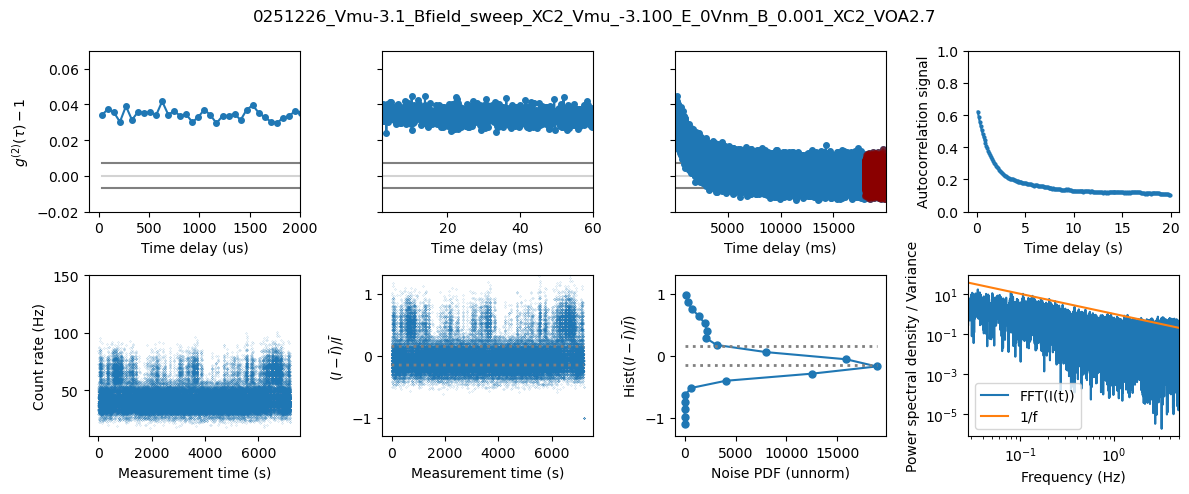

{'filepath': 'Q:\\g2_PH300\\20251224\\20251226_Vmu-3.1_Bfield_sweep_XC2\\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\\_chunk1.b', 'mode': 'A0', 'chunk_ms': 120000.0, 'tau_max_us': 20000000, 'tau_min_us': 0.2, 'tau_bin_ps': 2000000.0, 'n_chunks': 60}
Total msmt duration analyzed:  2.0  h
Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\_chunk1_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_9296\494680951.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


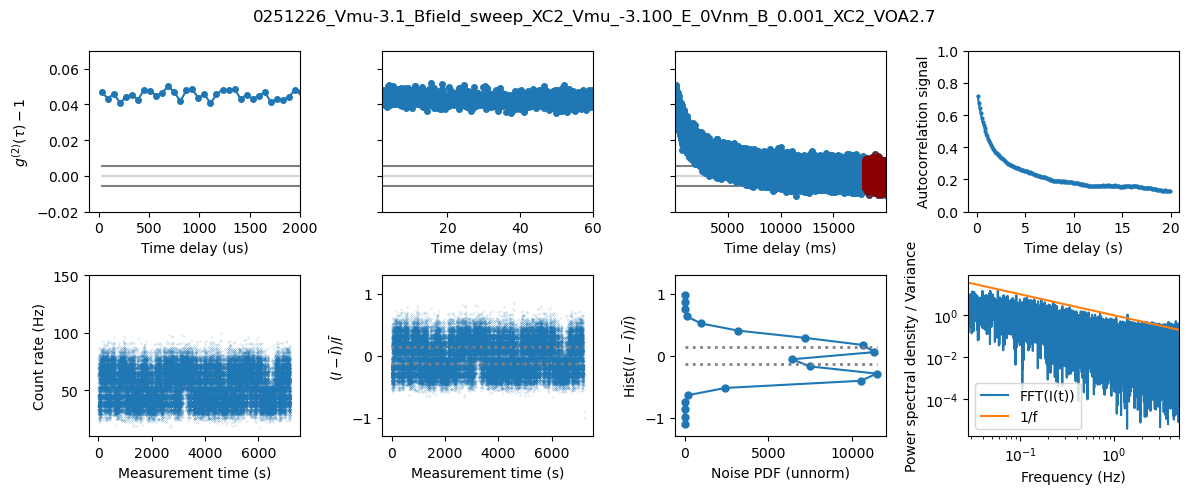

{'filepath': 'Q:\\g2_PH300\\20251224\\20251226_Vmu-3.1_Bfield_sweep_XC2\\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\\_chunk3.b', 'mode': 'A0', 'chunk_ms': 120000.0, 'tau_max_us': 20000000, 'tau_min_us': 0.2, 'tau_bin_ps': 2000000.0, 'n_chunks': 60}
Total msmt duration analyzed:  2.0  h
Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\_chunk2_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_9296\494680951.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


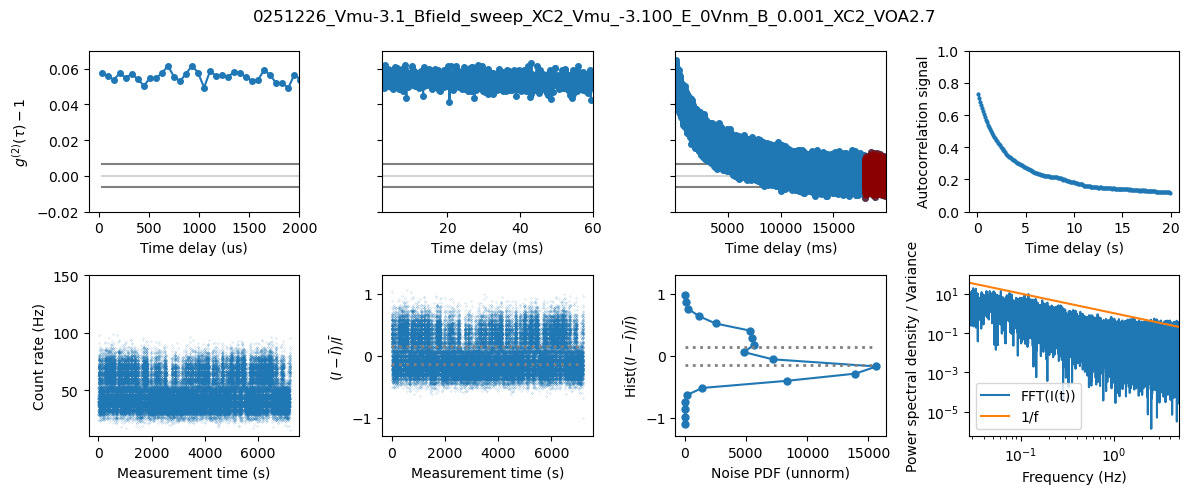

In [ ]:


### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
# Bs = np.arange(-0.008,-0.017,-0.001)[1:]
Bs = np.arange(0.001,-0.0051,-0.001)[:1]
# Bs = [0.001,0.000]
POL = "XC2"
# folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251223_Vmu-3.1_Bfield_sweep_'
# folder =r'Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_'
folder =r'Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_'
# folder =r'Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_'

chunk_mins = 2*60

# init = False
tau_max_us = 20_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0,1,2]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                    #                                             chunk_ms=120e3,    
                    #                                             tau_min_us= 0.2,     # tau max in microseconds
                    #                                             tau_max_us= tau_max_us,     
                    #                                             tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                    #                                             n_workers= max(1, 8-1), 
                    #                                             mode = g2mode,
                    #                                             show_progress=True)


                    # print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    # print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    # out_dir, files = analysis_cmd.correlate_b_file_classical(
                    #     filepath= filepath_b,
                    #     tau_bin_ms=tau_bin_ms,          
                    #     chunk_minutes=chunk_mins,    
                    #     block_records=20_000_000, 
                    #     include_channels=channel, # none = all channels
                    #     show_progress=True
                    # )

                    #### PLOT
                    g2_ylim = (-0.02,0.07)
                    counts_ylim = (10,150)
                    rebin_factor = 30

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection\Rep {c+1}")# None #None saves to the same directory as the b file
                                      )


# PLE with X* excitation: Same power, -16 mT $\rightarrow$ -8 mT at nu = =-1, E = 0

Finished correlating 274.838359 million records in file: Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_-0.016_XC2_VOA2.7\_chunk0.b
Total 2.019263827 billion coincidences in histogram
Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_-0.016_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13824\2251475889.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


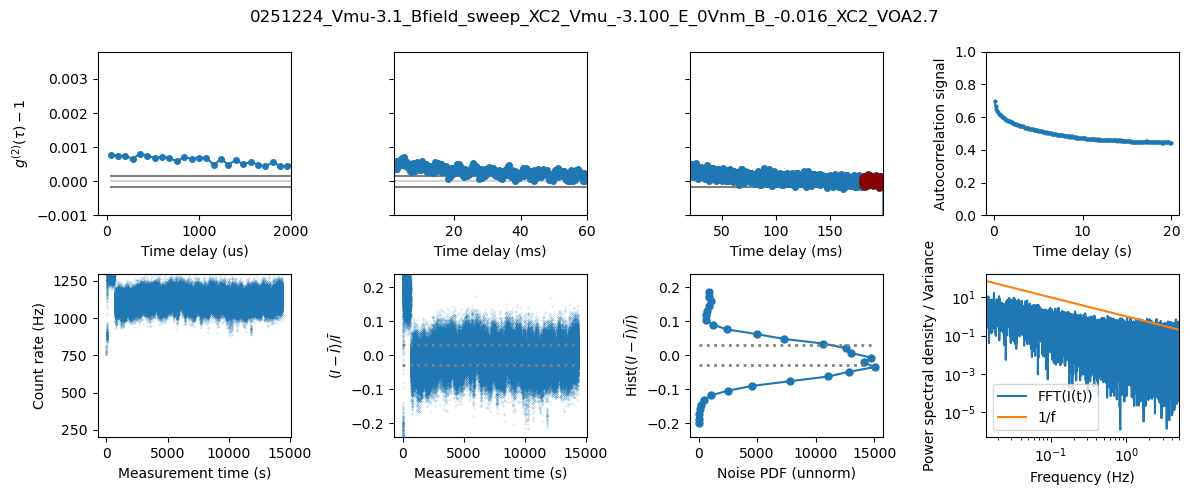

In [ ]:


### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
Bs = [-0.016]#np.arange(-0.008,-0.016,-0.001)
POL = "XC2"
folder =r'Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_'+POL
# folder =r'Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis'

chunk_mins = 4*60

# init = False
tau_max_us = 200_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)

            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=120e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)


                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    #### PLOT
                    g2_ylim = (-0.001,0.0038)
                    counts_ylim = (200,1300)
                    rebin_factor = 40#30
                    PDF_bins = np.linspace(-0.2,0.2,30)

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      PDF_bins = PDF_bins,
                                      savepath=   ntpath.join(folder,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


# PLE X* excitation like above; B = 1 mT $\rightarrow$ -5 mT 12hrs each

In [ ]:
analysis_cmd.clear_log()
analysis_setup()

------------------ LOG ------------------
[log cleared @ 2026-01-02 09:40:29]


Analysis server reached.
[ANALYSIS - UTC 2026-01-02 08:48:33] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:08] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:10] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:12] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:14] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.097_XC2_VOA2.1
[ANALYSIS - UTC 2026-01-02 08:49:15] Reading file with name _chunk0 in

In [ ]:
###### RUN THIS ON 31 JAN AFTERNOON

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
Bs = [-0.002,-0.003, -0.004]
POL = "XC2"
folder =r'Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_'

chunk_mins = 12*60

# init = False
tau_max_us = 20_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=120e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)
                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    # out_dir, files = analysis_cmd.correlate_b_file_classical(
                    #     filepath= filepath_b,
                    #     tau_bin_ms=tau_bin_ms,          
                    #     chunk_minutes=chunk_mins,    
                    #     block_records=20_000_000, 
                    #     include_channels=channel, # none = all channels
                    #     show_progress=True
                    # )

                    
                    #### PLOT
                    g2_ylim = None#(-0.02,0.07)
                    counts_ylim = None#(10,150)
                    rebin_factor = 240

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


MemoryError: 

Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13824\2253108541.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


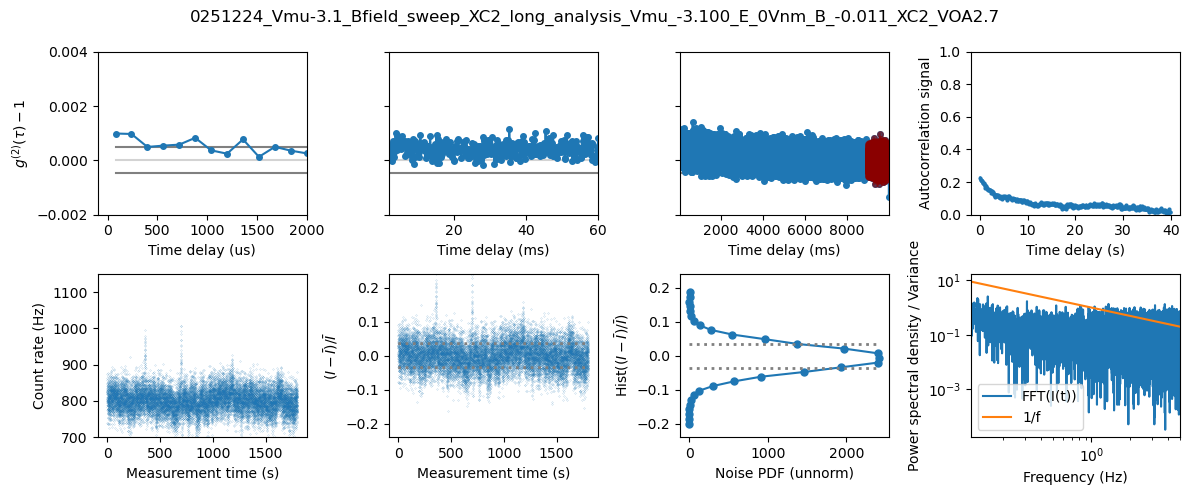

Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.012_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13824\2253108541.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


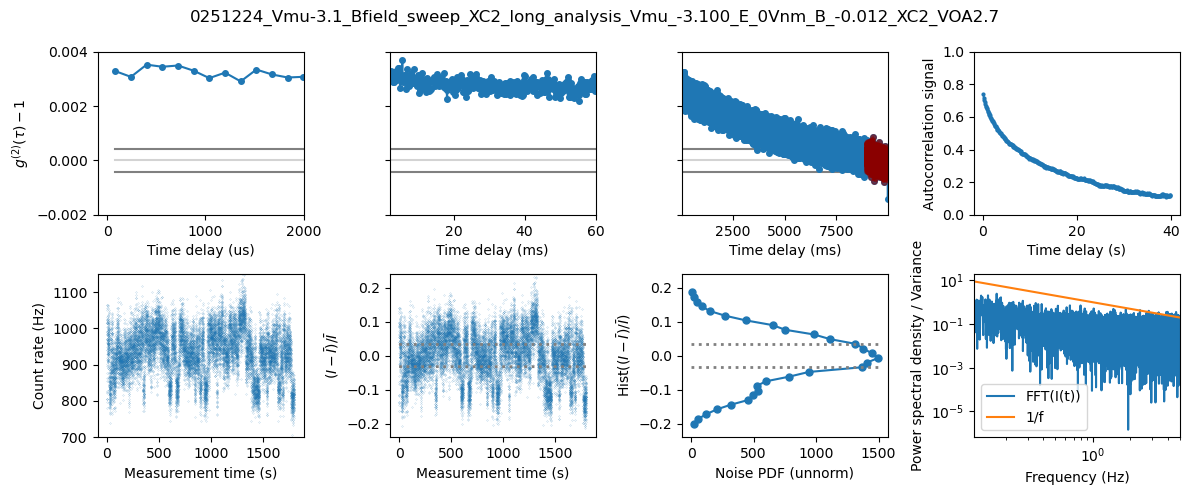

Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.013_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13824\2253108541.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


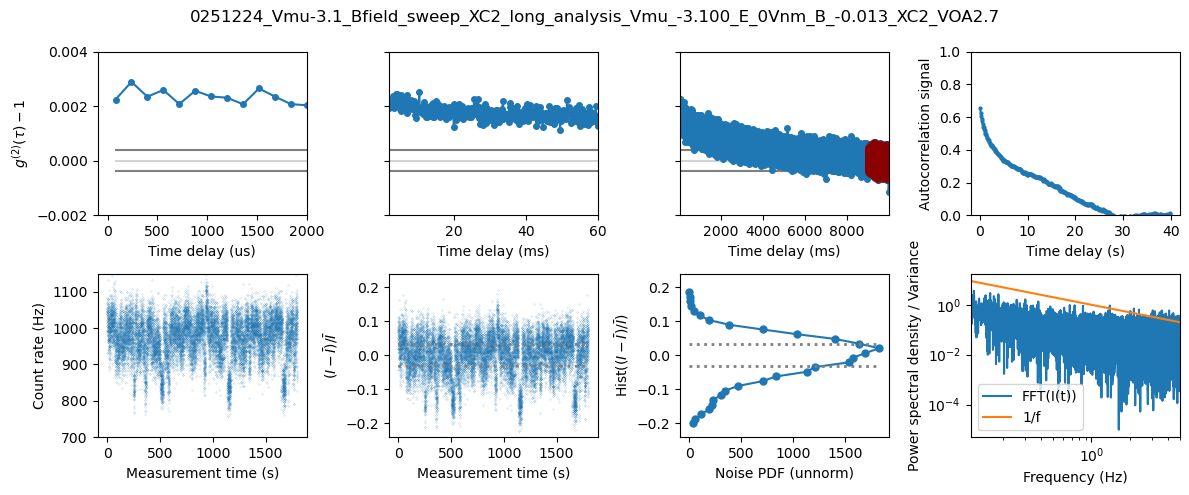

In [ ]:

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
POL = "XC2"

Bs = [-0.011,-0.012,-0.013]
folder =r'Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis'

# Bs = [0.001]
# folder =r'Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_XC2_long_analysis'

# folder =r'Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_'
# folder =r'Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_XC2'

chunk_mins = 30

# init = False
tau_max_us = 10_000_000

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                    #                                             chunk_ms=30e3,    
                    #                                             tau_min_us= 0.2,     # tau max in microseconds
                    #                                             tau_max_us= tau_max_us,     
                    #                                             tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                    #                                             n_workers= 7, 
                    #                                             mode = g2mode,
                    #                                             show_progress=True,
                    #                                             only_do_first_n_chunks=60
                    #                                             )
                    # print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    # print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    #### PLOT
                    g2_ylim = (-0.002,0.004)
                    counts_ylim = (700,1150)#(200,1300)
                    rebin_factor = 80#30
                    PDF_bins = np.linspace(-0.2,0.2,30)

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      PDF_bins = PDF_bins,
                                      savepath=   ntpath.join(folder,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


# Mapping out Xcirc2 with power and magnetic field

In [ ]:
.... should paste working code here from below
# folder =r'Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_'


# Investigating telegraph noise as a function of power

In [ ]:
analysis_cmd.clear_log()
analysis_setup()

------------------ LOG ------------------
[log cleared @ 2026-01-06 08:03:32]


Analysis server reached.
File Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.06\_chunk0.b: 42168001 records
mode=A0, chunk_ms=10000.0, tau_min=0.2us, tau_max=1000000us, bin=2000000.0ps
ticks: min=50000, max=250000000000, bin=500000, nbins=500000
Found 16016811 overflow markers.
Built 1350 chunks of length 10.00s, this took 1.4s.
Tasks100.0 % done, elapsed 267.8s  ETA 0.0sss
Correlation done in 268.1s; ch0=8594269, ch1=9452630
Correlation done.
[classical] File Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.06\_chunk0.b (42168001 records)
[classical] dt=100 ms (dt_ticks=25000000000), chunk=225 min (chunk_ticks=3375000000000000) -> 135000 bins/chunk including channels (none = all): 0.
 [classical autocorrelation] processed 100.0% (42168001/42168001) records
[classical] done in 1.9 s. Wrote 1 chunks to: Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.06\_chunk0_classical_bins
[ANALYS

Finished correlating 42.168001 million records in file: Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.06\_chunk0.b
Total 1.203635653 billion coincidences in histogram
Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.06\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_8224\1753170149.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


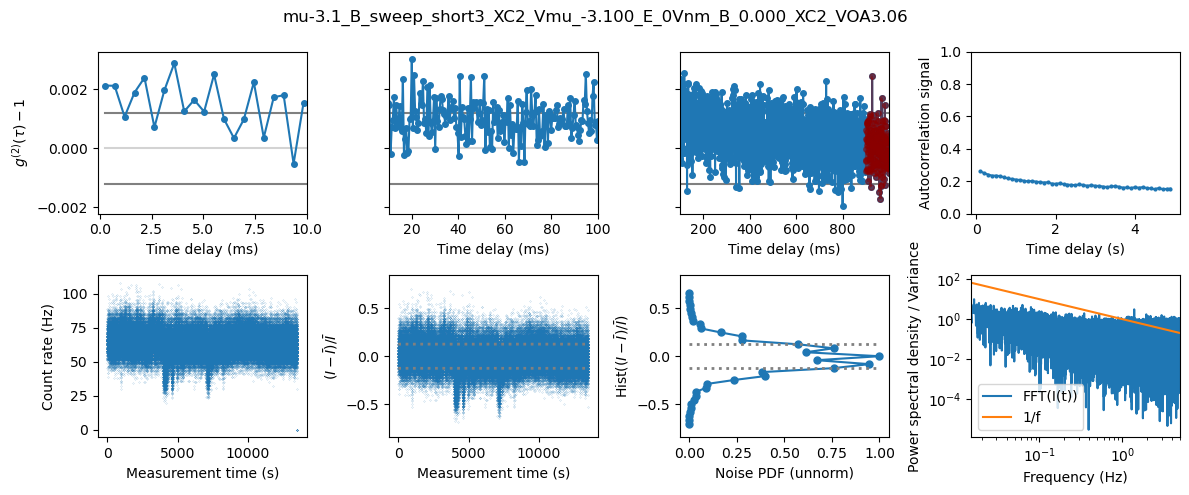

Finished correlating 49.192499 million records in file: Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.2\_chunk0.b
Total 1.384336362 billion coincidences in histogram
Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA3.2\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_8224\1753170149.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


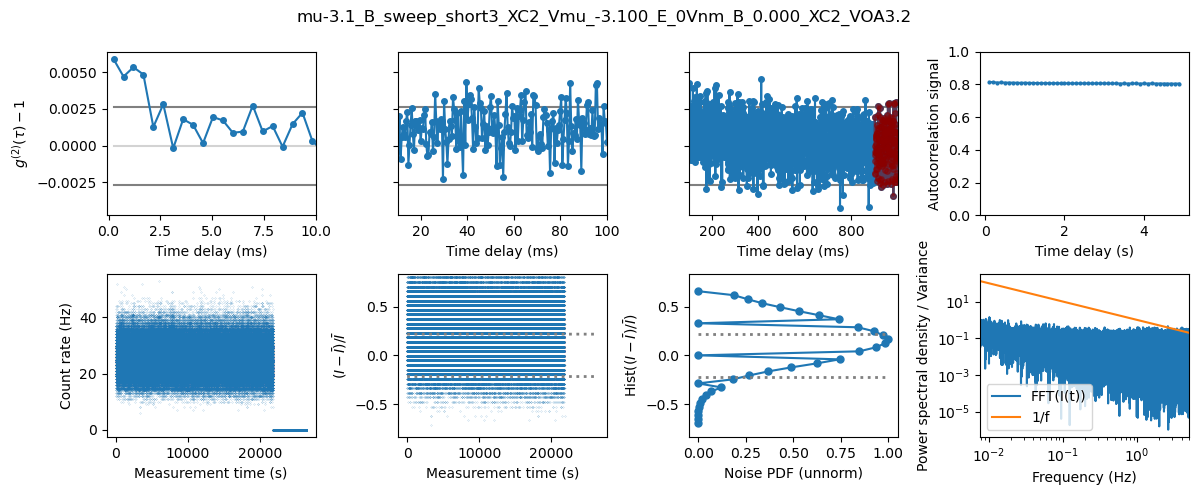

In [70]:
### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [3.06,3.2]#2.1,2.3,2.45,2.6,2.7,2.9]#,
durations_min = np.array([225,440])#4,7,12,20,33,92,])#
POL = "XC2"
Bs = np.array([0])#np.arange(0.25,-0.25,-0.001) 
folder =r'Q:\g2_PH300\20260105_Vmu-3.1_B_sweep_short3_'


# chunk_mins = DEFINED BELOW in voa loop

init = False
tau_max_us = 1_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=10e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)
                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=  durations_min[iv],    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    
                    # #### PLOT
                    g2_ylim = None#(-0.02,0.07)
                    counts_ylim = None#(10,150)
                    rebin_factor = 240
                    PDF_bins = np.linspace(-0.7,0.7,35)

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      PDF_bins = PDF_bins,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )
                    
                    # failed = False
                    # try:
                    #     cr, t = get_crs(paths, chunkname=f'_chunk{c}', include_channel = 0)
                    # except:
                    #     failed = True
                    # if not init:
                    #     cr_all = np.zeros((len(Bs), len(cr)))
                    #     init = True
                    # if not failed:
                    #     cr_all[iB,:] = cr
                    # else:
                    #     for i in range(len(cr_all[iB,:])):
                    #         cr_all[iB,i] = np.nan
                    
                    


# Analyzing power hysteresis msmt:


In [73]:
### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
Bs = [0]

from scipy.special import erf, erfinv
def voa_model(voa):
    return erf(-(voa-2.12))/2+1/2
    
def find_voa(target):
    return -erfinv( (target-1/2)*2)+2.12

ratios = np.concatenate((np.arange(0.95,0.01,-0.05),np.arange(0.01,0.96,0.05)))
voas = find_voa(ratios)
chunk_min = 2/60
POL = "XC2"

folder =r'Q:\g2_PH300\20260105_Vmu-3.1_powersweep1_'
chunks = np.arange(0,14,2)

# chunk_mins = DEFINED BELOW in voa loop

init = False
tau_max_us = 1_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for ic, c in enumerate(chunks):
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=10e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)
                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=  chunk_min,    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    
                    # #### PLOT
                    g2_ylim = None#(-0.02,0.07)
                    counts_ylim = None#(10,150)
                    rebin_factor = 240
                    PDF_bins = np.linspace(-0.7,0.7,35)

                    g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      PDF_bins = PDF_bins,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )
                    
                    failed = False
                    try:
                        cr, t = get_crs(paths, chunkname=f'_chunk{c}', include_channel = 0)
                    except:
                        failed = True
                    if not init:
                        cr_all = np.zeros((len(Bs), len(chunks), len(cr)))
                        init = True
                    if not failed:
                        cr_all[iB,ic,:] = cr
                    else:
                        for i in range(len(cr_all[iB,ic, :])):
                            cr_all[iB,ic, i] = np.nan
                    
                    


plt.plot(Bs, np.mean(cr_all, axis = 1))
Bs.shape, cr_all.shape

FileNotFoundError: [Errno 2] The system cannot find the path specified: 'Q:\\g2_PH300\\20260105_Vmu-3.1_powersweep1_XC2\\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA0.9569128463233263\\_chunk0.b'

In [ ]:
### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.4]
Bs = np.arange(0.1,-0.101,-0.001) 
POL = "XC2"
folder =r'Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_'

chunk_mins = 2.5

# init = False
tau_max_us = 1_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=10e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)
                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    
                    #### PLOT
                    g2_ylim = None#(-0.02,0.07)
                    counts_ylim = None#(10,150)
                    rebin_factor = 240

                    h,t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


{'filepath': 'Q:\\g2_PH300\\20251228_Vmu-3.1_Bfield_sweep_XC2\\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\\_chunk0.b', 'mode': 'A0', 'chunk_ms': 120000.0, 'tau_max_us': 20000000, 'tau_min_us': 0.2, 'tau_bin_ps': 2000000.0, 'n_chunks': 360}
Total msmt duration analyzed:  12.0  h
Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_0.001_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_9296\494680951.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


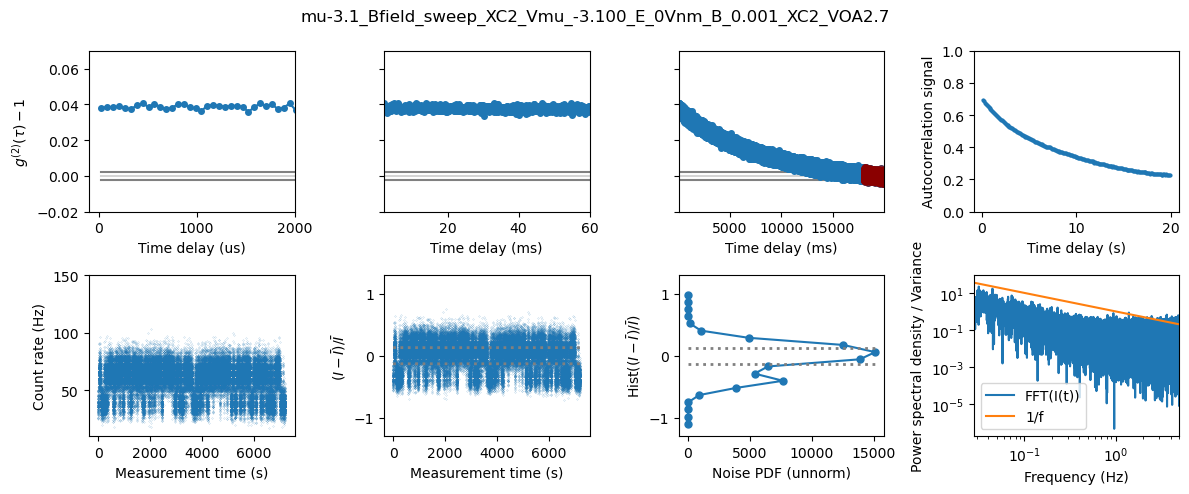

{'filepath': 'Q:\\g2_PH300\\20251228_Vmu-3.1_Bfield_sweep_XC2\\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA2.7\\_chunk0.b', 'mode': 'A0', 'chunk_ms': 120000.0, 'tau_max_us': 20000000, 'tau_min_us': 0.2, 'tau_bin_ps': 2000000.0, 'n_chunks': 360}
Total msmt duration analyzed:  12.0  h
Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_XC2\Vmu_-3.100_E_0Vnm_B_0.000_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_9296\494680951.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


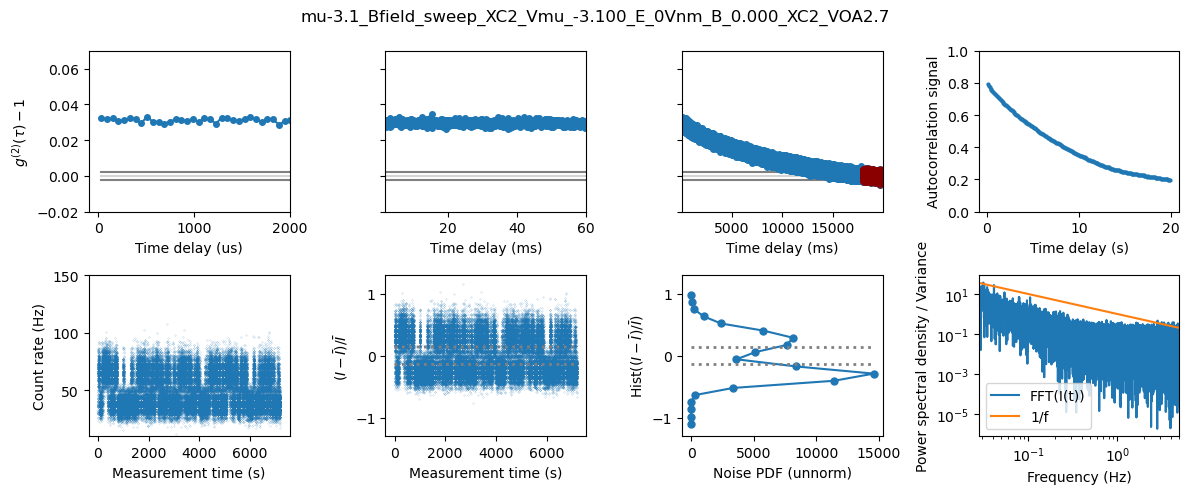

In [ ]:


### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
Bs = [0.001,0.000]
POL = "XC2"
folder =r'Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_'

chunk_mins = 2*60

# init = False
tau_max_us = 20_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                    #                                             chunk_ms=120e3,    
                    #                                             tau_min_us= 0.2,     # tau max in microseconds
                    #                                             tau_max_us= tau_max_us,     
                    #                                             tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                    #                                             n_workers= max(1, 8-1), 
                    #                                             mode = g2mode,
                    #                                             show_progress=True)


                    # print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    # print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    # out_dir, files = analysis_cmd.correlate_b_file_classical(
                    #     filepath= filepath_b,
                    #     tau_bin_ms=tau_bin_ms,          
                    #     chunk_minutes=chunk_mins,    
                    #     block_records=20_000_000, 
                    #     include_channels=channel, # none = all channels
                    #     show_progress=True
                    # )

                    
                    #### PLOT
                    g2_ylim = (-0.02,0.07)
                    counts_ylim = (10,150)
                    rebin_factor = 30

                    h,t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


In [ ]:
### INITIAL E SCAN AT VMUS AT VOA 3.1
Vmus = [-2.3,-2.6,-2.8,-3.1]
Es   = np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_'
chunk_mins = 1.95

### POWER SCAN AT BIMODAL FEATURE 2.8 V VMu, E = -0.2
Vmus = [-2.8]
Es   = [-0.02] ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.1]#[3.65,3.5,3.3,3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_test_'
chunk_mins = 3.5

### E SCAN AT Vmu = -3.1, several powers
Vmus = [-3.1]
Es   = np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_'
chunk_mins = 2.2

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_LINSP'
chunk_mins = 2.2

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_LINSM'
chunk_mins = 2.2


### B SCAN AT Vmu = -3.1, VE = 0
Bs = np.arange(-0.006,0.0061,0.001)
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [2.7]#,3.5,3.3,3.1]
POL = "XC2"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251222_Vmu-3.1_Bfield_sweep_'
chunk_mins = 2.2

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            print('E = %.4fV/nm'%Es[iE])
            name = os.path.join(folder+POL,  f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}") #{Es[iE]:.3f}
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            path = f"_chunk0.b"
            paths = (base, name, path)

            for g2mode, channel in zip(["A0","A1"],[0,1]):
                ### CALCULATE 
                
                filepath = ntpath.join(base, path)
                tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                            chunk_ms=20_000,    
                                                            tau_min_us= 0.2,     # tau max in microseconds
                                                            tau_max_us= 200_000,     
                                                            tau_bin_ps= 40e3,    # bin width in ps 
                                                            n_workers= 7,#max(1, 8-1), 
                                                            mode = g2mode,
                                                            show_progress=True)
                print(tau)
                print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                filepath_b = ntpath.join(base, path)

                tau_bin_ms = 5
                BASE_RES = 4e-12

                out_dir, files = analysis_cmd.correlate_b_file_classical(
                    filepath= filepath_b,
                    tau_bin_ms=tau_bin_ms,          
                    chunk_minutes=chunk_mins,    
                    block_records=10_000_000, 
                    include_channels=channel, # none = all channels
                    show_progress=True
                )


                #### PLOT
                h, t = analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk2", g2mode = g2mode, classical_channel=channel)

                if not init:
                    rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(h)),dtype = np.uint32)
                    times_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(t)),dtype = np.uint32)
                    init = True

                rates_all[iv,imu,iE,channel,:] = h
                times_all[iv,imu,iE,channel,:] = t

            

NameError: name 'iE' is not defined

In [ ]:
# without B-field sweep
def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    if ref_range_s is None:
        ref_range_s = [40e-3, 100e-3]
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[24:-6]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(20,200)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<20)],ac[(l>0) & (l<20)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    # plt.xlim(0,20)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(-1.1,1.1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    fig.savefig(ntpath.join(base,f"Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    return h_rebin_detrend, t_rebin


### VE SCAN at Vmu = -2.3, Bs = -2mT, Power = 70nW
Vmus = [-2.3]
Es   = [-0.054]#np.concatenate(([-0.02], np.arange(-0.04,-0.061,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.15]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251208_Esweep_Vmu-2.3_P_70nW_'
#voas = [2.85]
#folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251211_4K_Esweep_Vmu-2.3_'
chunk_mins = 60*3-0.2

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iE in range(len(Es)):
            print('E = %.4fV/nm'%Es[iE])
            name = os.path.join(folder+POL,  f"E_{Es[iE]:.3f}Vnm_{POL}_VOA{v}_70nW_window")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            path = f"_chunk0.b"
            paths = (base, name, path)

            for g2mode, channel in zip(["A0"],[0]):
                ### CALCULATE                     
                filepath = ntpath.join(base, path)
                tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                            chunk_ms=50_000,    
                                                            tau_min_us= 0.2,     # tau min in microseconds
                                                            tau_max_us= 200_000,     
                                                            tau_bin_ps= 40e3,    # bin width in ps 
                                                            n_workers= max(1, 8-1), 
                                                            mode = g2mode,
                                                            show_progress=True)

                print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                filepath_b = ntpath.join(base, path)

                tau_bin_ms = 5
                BASE_RES = 4e-12

                out_dir, files = analysis_cmd.correlate_b_file_classical(
                    filepath= filepath_b,
                    tau_bin_ms=tau_bin_ms,          
                    chunk_minutes=chunk_mins,    
                    block_records=10_000_000, 
                    include_channels=channel, # none = all channels
                    show_progress=True
                )

                #### PLOT
                #h, t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [0.8,1], include_channel = 0)
                h,t = analyze_all(paths, chunkname='_chunk0', g2mode = 'A0', ref_range_s = [150e-3,200e-3], include_channel = 0)
                #analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk0", g2mode = g2mode, classical_channel =channel)

                #if not init:
                #    rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(h)),dtype = np.uint32)
                #    times_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(t)),dtype = np.uint32)
                #    init = True

                #times_all[iv,imu,iE,channel,:] = t
                #rates_all[iv,imu,iE,channel,:] = h
                

            

E = -0.0540V/nm


NameError: name 'os' is not defined

In [ ]:
# With B-field sweep

def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    if ref_range_s is not None:
        ref_range_s = [40e-3, 100e-3]
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[24:-6]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(20,200)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<20)],ac[(l>0) & (l<20)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    # plt.xlim(0,20)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(-1.1,1.1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    fig.savefig(ntpath.join(base,f"Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    return h_rebin_detrend, t_rebin




### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.3]#,3.5,3.3,3.1]
Bs = np.arange(-0.041,-0.061,-0.001)
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_'
chunk_mins = 2.95

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iE in range(len(Es)):
            print('E = %.4fV/nm'%Es[iE])
            for iB in range(len(Bs)):
                name = os.path.join(folder+POL,  f"Vmu_{Vmus[imu]}_E_{Es[iE]:.3f}Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
                base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
                path = f"_chunk2.b"
                paths = (base, name, path)

                for g2mode, channel in zip(["A0"],[0]):
                    ### CALCULATE                     
                    filepath = ntpath.join(base, path)
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=120_000,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= 200_000,     
                                                                tau_bin_ps= 40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)

                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 5
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=10_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )


                    #### PLOT
                    #h, t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [0.8,1], include_channel = 0)
                    h,t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [1.8,2], include_channel = 0)
                    #analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk0", g2mode = g2mode, classical_channel =channel)

                    if not init:
                        rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(Bs),len(["A0","A1"]),len(h)),dtype = np.uint32)
                        times_all = np.zeros((len(voas),len(Vmus),len(Es),len(Bs),len(["A0","A1"]),len(t)),dtype = np.uint32)
                        init = True

                    rates_all[iv,imu,iE,iB,channel,:] = h
                    times_all[iv,imu,iE,iB,channel,:] = t

            

In [ ]:
analysis_setup()

In [ ]:
savefolder = os.path.join(folder+POL,"Analysis")

np.save(os.path.join(savefolder,"rates_all.npy"), rates_all)
np.save(os.path.join(savefolder,"times.npy"), times_all)
np.save(os.path.join(savefolder,"Bs.npy"), Bs)

rates_all.shape

In [ ]:
### ANALYZING THE B FIELD SCAN AT VMU = -3.1

# 
rates_all = np.load(os.path.join(savefolder,"rates_all.npy"))
Bs = np.load(os.path.join(savefolder,"Bs.npy"))
Vmus = [-3.1]
voas = [3.3]


mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.25)

fig, ax = plt.subplots(2,1,figsize = (4,8))
ax[0].set_title(f"Vmu = {Vmus[imu]}")
ax[0].plot(Bs, stdv[iv,imu,iE,:,0]/mean[iv,imu,iE,:,0],"-o",markersize = 4,label="PL",color='blue')
ax[0].plot(Bs, np.sqrt(mean[iv,imu,iE,:,0])/mean[iv,imu,iE,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

ax[0].plot(Bs, stdv[iv,imu,iE,:,1]/mean[iv,imu,iE,:,1],"-o",markersize = 4,label="Laser",color='grey')
ax[0].plot(Bs, np.sqrt(mean[iv,imu,iE,:,1])/mean[iv,imu,iE,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

ax[0].set_ylim(*ylims)
ax[0].set_ylabel("Std/Mean")
ax[0].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

ax[1].set_title(f"Vmu = {Vmus[imu]}")
ax[1].plot(Bs, mean[iv,imu,iE,:,0],"-o",markersize = 4,label="PL",color='blue')        
ax[1].plot(Bs, mean[iv,imu,iE,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
ax[1].set_ylim(*ylims)
ax[1].set_ylabel("Mean Count Rate")
ax[1].set_xlabel('Magnetic field (T)')
ax[1].legend()

fig.tight_layout()
fig.savefig(os.path.join(savefolder,"Fluctuations_Bscan_VOA3.3_Vmu-3.1.png"),dpi = 300)


In [ ]:

# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\rates_all.npy", rates_all)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\times.npy", times_all)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Es.npy", Es)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\voas.npy",voas)

#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\rates_all.npy", rates_all)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\times.npy", times_all)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Es.npy", Es)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\voas.npy",voas)


In [ ]:
### LONG VMU-VE scan
rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\countrates_all.npy")
Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\Es_all.npy")
Vmus = [-2.3,-2.6,-2.8,-3.1]
voas = [3.1]



# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,imu].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,imu].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,imu].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,imu].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,imu].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        ax[0,imu].set_ylim(*ylims)
        ax[0,imu].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,imu].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,imu].set_title(f"Vmu = {Vmus[imu]}")
        ax[1,imu].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,imu].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,imu].set_ylim(*ylims)
        ax[1,imu].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,imu].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\Fluctuations_Vmu_scan_VOA3.1.png")


In [ ]:

# Short power scan at E = -0.02 V/nm, Vmu = -2.8 V
# rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_LINSP\Analysis\rates_all_powerscan_E-0.02_Vmu-2.8.npy")
# voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_LINSP\Analysis\voas_all_powerscan_E-0.02_Vmu-2.8.npy")
# Vmus = [-2.8]

print(voas)

In [ ]:
### Analyzing the power-E sweep at Vmu = -3.1
rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\rates_all.npy")
times_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\times.npy")
Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Es.npy")
voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\voas.npy")
Vmus = [-3.1]


# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,iv].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,iv].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,iv].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        ax[0,iv].set_ylim(*ylims)
        ax[0,iv].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,iv].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,iv].set_title(f"VOA = {voas[iv]}")
        ax[1,iv].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,iv].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,iv].set_ylim(*ylims)
        ax[1,iv].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,iv].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Fluctuations_E_VOA_scan_Vmu-3.1.png")


In [ ]:
### Analyzing the power-E sweep at Vmu = -3.1 in LINSM
# rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\rates_all.npy")
# times_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\times.npy")
# Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Es.npy")
# voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\voas.npy")
Vmus = [-3.1]


# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,iv].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,iv].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,iv].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        # ax[0,iv].set_ylim(*ylims)
        ax[0,iv].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,iv].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,iv].set_title(f"VOA = {voas[iv]}")
        ax[1,iv].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,iv].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,iv].set_ylim(*ylims)
        ax[1,iv].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,iv].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Fluctuations_E_VOA_scan_Vmu-3.1.png")


# Investigating few-ms oscillations in g2

In [ ]:
analysis_setup()

In [ ]:
def analyze_osci_g2(paths, ref_range_s,chunkname='all', g2mode = "all"):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(np.max(tau)/500e-6)
    
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    signal = h_rebin_detrend
    signal_fft = fft(signal)[1:len(tau_rebin)//2]
    dt = np.diff(tau_rebin)
    freqs = fftfreq(len(tau_rebin)-1, dt)[1:len(tau_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2

    fig, ax = plt.subplots(1,2,figsize = (12,3))
    pltname = name.strip("\\").replace("\\", "_")[:-6]
    fig.suptitle(pltname+"\n"+f"Mode {g2mode}")
    
    plt.sca(ax[0])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-0.1,600)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$"+f"(Mode {g2mode})")
    plt.xlabel("Time delay (ms)")


    plt.sca(ax[1])
    plt.plot(freqs, signal_fft)
    plt.ylabel(r"FFT$(g^{(2)}(tau)$")
    plt.xlabel("Frequency (Hz)")
    plt.xlim(0,200)
    plt.tight_layout()
    fig.savefig(ntpath.join(base,f"Fourier_Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    fig.savefig(ntpath.join(r"C:\Users\SSPDs\Documents\Offline SSPD Data\Fourier Analysis", f"Fourier_Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    plt.show()

In [ ]:
Es = np.arange(-0.045,-0.065,-0.001)
Es =Es[Es>-0.057]
names = [r"20251204_Vmu-2.3_test_LINSP\Vmu_-2.6_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.1" for E in Es]
chunks = np.zeros_like(names,dtype = int)



#Es = np.concatenate((np.arange(0,-0.04,-0.005), np.arange(-0.040,-0.064,-0.001)))
#Es = [-0.049,-0.05,-0.051]
#names = [r"20251120_Esweep_Vmu-2.3_LINSP\E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.3_114nW_window\tests" for E in Es]
#chunks = np.zeros_like(Es,dtype=int)

## VOA SCAN
#voas = np.array([2.9,3.0,3.1,3.3,3.35,3.4,3.45,3.5])# 2.9, 3.0
#names = [r"20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_"+f"{v}"+r"_LINSP\tests" for v in voas]
#chunks = np.zeros_like(voas,dtype=int)


## B SCAN
Bs = np.arange(0.001,-0.01,-0.001)
names = [r"20251124_Bsweep_Vmu-2.3_E-0.05_LINSP\B_"+f"{B:.3f}"+r"_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests" for B in Bs]
chunks = np.zeros_like(Bs,dtype=int)


## LOW POWER -3.1 VMu
Es = [-0.117,-0.116,-0.115]
names = [r"20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.65" for E in Es]
chunks = np.zeros_like(names,dtype = int)



for name, c in zip(names,chunks):
    #home = r'Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations'
    home = r'C:\Users\SSPDs\Documents\Offline SSPD Data'
    
    base = os.path.join(home,name)
    path = f"_chunk{c:d}.b"

    ch = 0
    g2mode = f"A{ch}"
    ref_range_s = None#[0.4,0.6]
    
    paths = (base, name, path)
    analyze_osci_g2(paths, ref_range_s, chunkname = f"_chunk{c:d}", g2mode = g2mode)
    

In [ ]:
ref_range_s =[0.4,0.6]
    
paths = (base, name, path)
analyze_osci_g2(paths, ref_range_s, chunkname = f"_chunk{c:d}", g2mode = g2mode)

In [ ]:
### INITIAL E SCAN AT VMUS AT VOA 3.1
Vmus = [-2.3,-2.6,-2.8,-3.1]
Es   = np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_'
chunk_mins = 1.95

### POWER SCAN AT BIMODAL FEATURE 2.8 V VMu, E = -0.2
Vmus = [-2.8]
Es   = [-0.02] ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.1]#[3.65,3.5,3.3,3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_test_'
chunk_mins = 3.5

### E SCAN AT Vmu = -3.1, several powers
Vmus = [-3.1]
Es   = np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_'
chunk_mins = 2.2

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_LINSP'
chunk_mins = 2.2

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.65]#,3.5,3.3,3.1]
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_LINSM'
chunk_mins = 2.2


### B SCAN AT Vmu = -3.1, VE = 0
Bs = np.arange(-0.006,0.0061,0.001)
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [2.7]#,3.5,3.3,3.1]
POL = "XC2"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251222_Vmu-3.1_Bfield_sweep_'
chunk_mins = 2.2

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            print('E = %.4fV/nm'%Es[iE])
            name = os.path.join(folder+POL,  f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}") #{Es[iE]:.3f}
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            path = f"_chunk0.b"
            paths = (base, name, path)

            for g2mode, channel in zip(["A0","A1"],[0,1]):
                ### CALCULATE 
                
                filepath = ntpath.join(base, path)
                tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                            chunk_ms=20_000,    
                                                            tau_min_us= 0.2,     # tau max in microseconds
                                                            tau_max_us= 200_000,     
                                                            tau_bin_ps= 40e3,    # bin width in ps 
                                                            n_workers= 7,#max(1, 8-1), 
                                                            mode = g2mode,
                                                            show_progress=True)
                print(tau)
                print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                filepath_b = ntpath.join(base, path)

                tau_bin_ms = 5
                BASE_RES = 4e-12

                out_dir, files = analysis_cmd.correlate_b_file_classical(
                    filepath= filepath_b,
                    tau_bin_ms=tau_bin_ms,          
                    chunk_minutes=chunk_mins,    
                    block_records=10_000_000, 
                    include_channels=channel, # none = all channels
                    show_progress=True
                )


                #### PLOT
                h, t = analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk2", g2mode = g2mode, classical_channel=channel)

                if not init:
                    rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(h)),dtype = np.uint32)
                    times_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(t)),dtype = np.uint32)
                    init = True

                rates_all[iv,imu,iE,channel,:] = h
                times_all[iv,imu,iE,channel,:] = t

            

NameError: name 'iE' is not defined

In [2]:
# without B-field sweep
def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    if ref_range_s is None:
        ref_range_s = [40e-3, 100e-3]
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[24:-6]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(20,200)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<20)],ac[(l>0) & (l<20)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    # plt.xlim(0,20)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(-1.1,1.1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    fig.savefig(ntpath.join(base,f"Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    return h_rebin_detrend, t_rebin


### VE SCAN at Vmu = -2.3, Bs = -2mT, Power = 70nW
Vmus = [-2.3]
Es   = [-0.054]#np.concatenate(([-0.02], np.arange(-0.04,-0.061,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.15]
POL = "LINSP"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251208_Esweep_Vmu-2.3_P_70nW_'
#voas = [2.85]
#folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251211_4K_Esweep_Vmu-2.3_'
chunk_mins = 60*3-0.2

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iE in range(len(Es)):
            print('E = %.4fV/nm'%Es[iE])
            name = os.path.join(folder+POL,  f"E_{Es[iE]:.3f}Vnm_{POL}_VOA{v}_70nW_window")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            path = f"_chunk0.b"
            paths = (base, name, path)

            for g2mode, channel in zip(["A0"],[0]):
                ### CALCULATE                     
                filepath = ntpath.join(base, path)
                tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                            chunk_ms=50_000,    
                                                            tau_min_us= 0.2,     # tau min in microseconds
                                                            tau_max_us= 200_000,     
                                                            tau_bin_ps= 40e3,    # bin width in ps 
                                                            n_workers= max(1, 8-1), 
                                                            mode = g2mode,
                                                            show_progress=True)

                print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                filepath_b = ntpath.join(base, path)

                tau_bin_ms = 5
                BASE_RES = 4e-12

                out_dir, files = analysis_cmd.correlate_b_file_classical(
                    filepath= filepath_b,
                    tau_bin_ms=tau_bin_ms,          
                    chunk_minutes=chunk_mins,    
                    block_records=10_000_000, 
                    include_channels=channel, # none = all channels
                    show_progress=True
                )

                #### PLOT
                #h, t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [0.8,1], include_channel = 0)
                h,t = analyze_all(paths, chunkname='_chunk0', g2mode = 'A0', ref_range_s = [150e-3,200e-3], include_channel = 0)
                #analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk0", g2mode = g2mode, classical_channel =channel)

                #if not init:
                #    rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(h)),dtype = np.uint32)
                #    times_all = np.zeros((len(voas),len(Vmus),len(Es),len(["A0","A1"]),len(t)),dtype = np.uint32)
                #    init = True

                #times_all[iv,imu,iE,channel,:] = t
                #rates_all[iv,imu,iE,channel,:] = h
                

            

E = -0.0540V/nm


NameError: name 'os' is not defined

In [ ]:
# With B-field sweep

def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    if ref_range_s is not None:
        ref_range_s = [40e-3, 100e-3]
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[24:-6]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(20,200)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<20)],ac[(l>0) & (l<20)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    # plt.xlim(0,20)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(-1.1,1.1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    fig.savefig(ntpath.join(base,f"Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    return h_rebin_detrend, t_rebin




### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0] #np.concatenate((np.arange(0,-0.04,-0.010), np.arange(-0.03,-0.146,-0.001))) ## should only be negative, starting closest to zero, for the initialization to make sense
voas = [3.3]#,3.5,3.3,3.1]
Bs = np.arange(-0.041,-0.061,-0.001)
POL = "LINSM"
folder = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251205_Vmu-3.1_Bfield_sweep_'
chunk_mins = 2.95

init = False

for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iE in range(len(Es)):
            print('E = %.4fV/nm'%Es[iE])
            for iB in range(len(Bs)):
                name = os.path.join(folder+POL,  f"Vmu_{Vmus[imu]}_E_{Es[iE]:.3f}Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
                base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
                path = f"_chunk2.b"
                paths = (base, name, path)

                for g2mode, channel in zip(["A0"],[0]):
                    ### CALCULATE                     
                    filepath = ntpath.join(base, path)
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=120_000,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= 200_000,     
                                                                tau_bin_ps= 40e3,    # bin width in ps 
                                                                n_workers= max(1, 8-1), 
                                                                mode = g2mode,
                                                                show_progress=True)

                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 5
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=10_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )


                    #### PLOT
                    #h, t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [0.8,1], include_channel = 0)
                    h,t = analyze_all(paths, chunkname='_chunk2', g2mode = 'A0', ref_range_s = [1.8,2], include_channel = 0)
                    #analyze_all_gatemap(paths,ref_range_s=[0.1e-3,0.2e-3],chunkname = f"_chunk0", g2mode = g2mode, classical_channel =channel)

                    if not init:
                        rates_all = np.zeros((len(voas),len(Vmus),len(Es),len(Bs),len(["A0","A1"]),len(h)),dtype = np.uint32)
                        times_all = np.zeros((len(voas),len(Vmus),len(Es),len(Bs),len(["A0","A1"]),len(t)),dtype = np.uint32)
                        init = True

                    rates_all[iv,imu,iE,iB,channel,:] = h
                    times_all[iv,imu,iE,iB,channel,:] = t

            

In [ ]:
analysis_setup()

In [ ]:
savefolder = os.path.join(folder+POL,"Analysis")

np.save(os.path.join(savefolder,"rates_all.npy"), rates_all)
np.save(os.path.join(savefolder,"times.npy"), times_all)
np.save(os.path.join(savefolder,"Bs.npy"), Bs)

rates_all.shape

In [ ]:
### ANALYZING THE B FIELD SCAN AT VMU = -3.1

# 
rates_all = np.load(os.path.join(savefolder,"rates_all.npy"))
Bs = np.load(os.path.join(savefolder,"Bs.npy"))
Vmus = [-3.1]
voas = [3.3]


mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.25)

fig, ax = plt.subplots(2,1,figsize = (4,8))
ax[0].set_title(f"Vmu = {Vmus[imu]}")
ax[0].plot(Bs, stdv[iv,imu,iE,:,0]/mean[iv,imu,iE,:,0],"-o",markersize = 4,label="PL",color='blue')
ax[0].plot(Bs, np.sqrt(mean[iv,imu,iE,:,0])/mean[iv,imu,iE,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

ax[0].plot(Bs, stdv[iv,imu,iE,:,1]/mean[iv,imu,iE,:,1],"-o",markersize = 4,label="Laser",color='grey')
ax[0].plot(Bs, np.sqrt(mean[iv,imu,iE,:,1])/mean[iv,imu,iE,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

ax[0].set_ylim(*ylims)
ax[0].set_ylabel("Std/Mean")
ax[0].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

ax[1].set_title(f"Vmu = {Vmus[imu]}")
ax[1].plot(Bs, mean[iv,imu,iE,:,0],"-o",markersize = 4,label="PL",color='blue')        
ax[1].plot(Bs, mean[iv,imu,iE,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
ax[1].set_ylim(*ylims)
ax[1].set_ylabel("Mean Count Rate")
ax[1].set_xlabel('Magnetic field (T)')
ax[1].legend()

fig.tight_layout()
fig.savefig(os.path.join(savefolder,"Fluctuations_Bscan_VOA3.3_Vmu-3.1.png"),dpi = 300)


In [ ]:

# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\rates_all.npy", rates_all)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\times.npy", times_all)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Es.npy", Es)
# np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\voas.npy",voas)

#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\rates_all.npy", rates_all)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\times.npy", times_all)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Es.npy", Es)
#np.save(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\voas.npy",voas)


In [ ]:
### LONG VMU-VE scan
rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\countrates_all.npy")
Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\Es_all.npy")
Vmus = [-2.3,-2.6,-2.8,-3.1]
voas = [3.1]



# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,imu].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,imu].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,imu].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,imu].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,imu].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        ax[0,imu].set_ylim(*ylims)
        ax[0,imu].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,imu].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,imu].set_title(f"Vmu = {Vmus[imu]}")
        ax[1,imu].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,imu].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,imu].set_ylim(*ylims)
        ax[1,imu].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,imu].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_gatevoltage_map_LINSP\Analysis\Fluctuations_Vmu_scan_VOA3.1.png")


In [ ]:

# Short power scan at E = -0.02 V/nm, Vmu = -2.8 V
# rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_LINSP\Analysis\rates_all_powerscan_E-0.02_Vmu-2.8.npy")
# voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251201_powerdep_LINSP\Analysis\voas_all_powerscan_E-0.02_Vmu-2.8.npy")
# Vmus = [-2.8]

print(voas)

In [ ]:
### Analyzing the power-E sweep at Vmu = -3.1
rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\rates_all.npy")
times_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\times.npy")
Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Es.npy")
voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\voas.npy")
Vmus = [-3.1]


# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,iv].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,iv].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,iv].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        ax[0,iv].set_ylim(*ylims)
        ax[0,iv].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,iv].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,iv].set_title(f"VOA = {voas[iv]}")
        ax[1,iv].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,iv].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,iv].set_ylim(*ylims)
        ax[1,iv].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,iv].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251202_Vmu-3.1_Escan_LINSP\Analysis\Fluctuations_E_VOA_scan_Vmu-3.1.png")


In [ ]:
### Analyzing the power-E sweep at Vmu = -3.1 in LINSM
# rates_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\rates_all.npy")
# times_all = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\times.npy")
# Es = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Es.npy")
# voas = np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\voas.npy")
Vmus = [-3.1]


# t = times_all[iv,imu,0,ch,:]
mean = np.mean(rates_all,axis = -1)
stdv = np.std( rates_all,axis = -1)
ylims = (0,max(np.max(stdv[:,:,:,0]/mean[:,:,:,0]),np.max(stdv[:,:,:,1]/mean[:,:,:,1]))*1.1)

fig, ax = plt.subplots(2,4,figsize = (12,8))
for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[0,iv].set_title(f"Vmu = {Vmus[imu]}")
        ax[0,iv].plot(Es, stdv[iv,imu,:,0]/mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,0])/mean[iv,imu,:,0],"--",markersize = 4,label=r"PL $\sqrt{I}/I$",color='darkblue')

        ax[0,iv].plot(Es, stdv[iv,imu,:,1]/mean[iv,imu,:,1],"-o",markersize = 4,label="Laser",color='grey')
        ax[0,iv].plot(Es, np.sqrt(mean[iv,imu,:,1])/mean[iv,imu,:,1],"--",markersize = 4,label=r"Laser $\sqrt{I}/I$",color='black')

        # ax[0,iv].set_ylim(*ylims)
        ax[0,iv].set_ylabel("Std/Mean")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[0,iv].legend()

ylims = (0,max(np.max(mean[:,:,:,0]),np.max(mean[:,:,:,1]/100))*1.1)

for imu in range(len(Vmus)):
    for iv in range(len(voas)):
        ax[1,iv].set_title(f"VOA = {voas[iv]}")
        ax[1,iv].plot(Es, mean[iv,imu,:,0],"-o",markersize = 4,label="PL",color='blue')        
        ax[1,iv].plot(Es, mean[iv,imu,:,1]/100,"-o",markersize = 4,label="Laser / 100",color='grey')
        ax[1,iv].set_ylim(*ylims)
        ax[1,iv].set_ylabel("Mean Count Rate")
        # ax[imu].set_xlim(-0.08,-0.03)
ax[1,iv].legend()

fig.tight_layout()
fig.savefig(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_Escan_LINSM\Analysis\Fluctuations_E_VOA_scan_Vmu-3.1.png")


# Investigating few-ms oscillations in g2

In [ ]:
analysis_setup()

In [ ]:
def analyze_osci_g2(paths, ref_range_s,chunkname='all', g2mode = "all"):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(np.max(tau)/500e-6)
    
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    signal = h_rebin_detrend
    signal_fft = fft(signal)[1:len(tau_rebin)//2]
    dt = np.diff(tau_rebin)
    freqs = fftfreq(len(tau_rebin)-1, dt)[1:len(tau_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2

    fig, ax = plt.subplots(1,2,figsize = (12,3))
    pltname = name.strip("\\").replace("\\", "_")[:-6]
    fig.suptitle(pltname+"\n"+f"Mode {g2mode}")
    
    plt.sca(ax[0])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-0.1,600)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$"+f"(Mode {g2mode})")
    plt.xlabel("Time delay (ms)")


    plt.sca(ax[1])
    plt.plot(freqs, signal_fft)
    plt.ylabel(r"FFT$(g^{(2)}(tau)$")
    plt.xlabel("Frequency (Hz)")
    plt.xlim(0,200)
    plt.tight_layout()
    fig.savefig(ntpath.join(base,f"Fourier_Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    fig.savefig(ntpath.join(r"C:\Users\SSPDs\Documents\Offline SSPD Data\Fourier Analysis", f"Fourier_Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    plt.show()

In [ ]:
Es = np.arange(-0.045,-0.065,-0.001)
Es =Es[Es>-0.057]
names = [r"20251204_Vmu-2.3_test_LINSP\Vmu_-2.6_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.1" for E in Es]
chunks = np.zeros_like(names,dtype = int)



#Es = np.concatenate((np.arange(0,-0.04,-0.005), np.arange(-0.040,-0.064,-0.001)))
#Es = [-0.049,-0.05,-0.051]
#names = [r"20251120_Esweep_Vmu-2.3_LINSP\E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.3_114nW_window\tests" for E in Es]
#chunks = np.zeros_like(Es,dtype=int)

## VOA SCAN
#voas = np.array([2.9,3.0,3.1,3.3,3.35,3.4,3.45,3.5])# 2.9, 3.0
#names = [r"20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_"+f"{v}"+r"_LINSP\tests" for v in voas]
#chunks = np.zeros_like(voas,dtype=int)


## B SCAN
Bs = np.arange(0.001,-0.01,-0.001)
names = [r"20251124_Bsweep_Vmu-2.3_E-0.05_LINSP\B_"+f"{B:.3f}"+r"_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests" for B in Bs]
chunks = np.zeros_like(Bs,dtype=int)


## LOW POWER -3.1 VMu
Es = [-0.117,-0.116,-0.115]
names = [r"20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.65" for E in Es]
chunks = np.zeros_like(names,dtype = int)



for name, c in zip(names,chunks):
    #home = r'Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations'
    home = r'C:\Users\SSPDs\Documents\Offline SSPD Data'
    
    base = os.path.join(home,name)
    path = f"_chunk{c:d}.b"

    ch = 0
    g2mode = f"A{ch}"
    ref_range_s = None#[0.4,0.6]
    
    paths = (base, name, path)
    analyze_osci_g2(paths, ref_range_s, chunkname = f"_chunk{c:d}", g2mode = g2mode)
    

In [ ]:
ref_range_s =[0.4,0.6]
    
paths = (base, name, path)
analyze_osci_g2(paths, ref_range_s, chunkname = f"_chunk{c:d}", g2mode = g2mode)